# 03 · MODIS reproduction: satellite models and the 28.06% ensemble

**Purpose.** Rerun the intern's last three rounds and check them against the write-up:

| Section | What | Intern's headline |
|---|---|---|
| 1 | Five model families using the satellite features from notebook 02 | 26.16–28.00% |
| 2 | Combining them: one model per starting class, then **averaging probabilities** | 27.87% → **28.06%** |
| 3 | Model-free rules: how far a rule with no training gets | 22.70% |
| 4 | Scoring against a temporally cleaned reference map | 15.32% |

**Selection protocol for this round**: fit
2010→2015 in the 95 training blocks; choose the model and its decision thresholds
on 2010→2015 in the 41 *held-out* blocks (same period, different place); freeze;
forecast 2015→2020. The yardstick is the **RF control from notebook 01 §5,
26.84%** (intern 26.93%): same protocol, no satellite data.

**Package versions.** Every model in this notebook is rerun with the intern's package versions (Python 3.14, xgboost 3.4.1, scikit-learn 1.9.0; `local_landuse/requirements-intern.txt`) in a separate environment (README). Notebook 01 §4 shows why: versions alone move threshold-tuned XGBoost forecasts by up to 0.85 points.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
RERUN = {"families": False,   # ~4 h for all five
         "ensembles": False,  # ~45 min
         "rules": False,      # ~2 min
         "hmm": False}        # ~5 min
M, L = "data/modis", "data/landsat"
PY, S = H.INTERN_PY, H.INTERN_SUFFIX   # intern's package versions; saved runs end in "_py314"
H.RERUN_LABEL = H.RERUN_PY314         # how this notebook's rerun columns are labelled

def load_family(run):
    report = json.loads((run / "report.json").read_text())
    final = H.read_csv(run / "final_comparison.csv")
    validation = {r["name"]: r["figure_of_merit_pct"] for r in report["validation"]}
    return report, final, validation

lc15, _ = H.read_map("Guinea_LandCover_2015.tif")
lc20, _ = H.read_map("Guinea_LandCover_2020.tif")
f, a = "figure_of_merit_pct", "overall_accuracy"

## 1 · Five satellite-feature model families

Each family runs the same set of candidate models (RF and XGBoost; next-class,
two-stage and relative-action structures; "expanded" variants trained on up to
300,000 pixels instead of 67,938) with a different feature set:

| Family | Features added to land-cover history |
|---|---|
| Seasonal MODIS | 12-period NDVI/EVI, seasonal means, annual harmonic, 5-year trend |
| MODIS + neighbourhood | the above, plus 3×3 and 15×15 neighbourhood means, variability and contrast |
| Landsat | dry-season reflectance, NDVI/NDMI/NBR, trend, neighbourhood statistics |
| Combined | MODIS + neighbourhood + Landsat |
| Class typicality | how well a pixel's seasonal curve fits its own labelled class, and which class it resembles more |

In [2]:
families = [  # (module, saved run, label, extra args, intern validation, intern forecast)
    ("local_landuse.phenology_models", "phenology_models_20260910", "Seasonal MODIS",
     ["--phenology-dir", M], 35.75, 27.50),
    ("local_landuse.vegetation_context", "vegetation_context_20260910", "MODIS + neighbourhood",
     ["--phenology-dir", M], 36.06, 28.00),
    ("local_landuse.spectral_models", "spectral_models_20260910", "Landsat",
     ["--spectral-dir", L], 34.38, 26.16),
    ("local_landuse.vegetation_context", "fused_satellite_20260910", "Combined MODIS + Landsat",
     ["--phenology-dir", M, "--spectral-dir", L], 36.24, 27.87),
    ("local_landuse.class_typicality", "typicality_20260910", "Class typicality",
     ["--phenology-dir", M, "--spectral-dir", L], 36.34, 27.25),
]
runs, rows = {}, []
for module, name, label, args, iv, ifc in families:
    run = H.ensure_run(module, name + S, args, RERUN["families"], python=PY)
    runs[name] = run
    report, final, val = load_family(run)
    sel = report["selected_model"]
    rows.append((label, sel, iv, val[sel], ifc, H.row(final, "name", sel, f)))
fam = pd.DataFrame(rows, columns=["Family", "Selected on validation", "Intern val. %", "Ours val. %",
                                  "Intern FoM %", "Ours FoM %"])
fam["Δ FoM (pts)"] = fam["Ours FoM %"] - fam["Intern FoM %"]
H.show(fam)

Using saved: outputs/phenology_models_20260910_py314
Using saved: outputs/vegetation_context_20260910_py314
Using saved: outputs/spectral_models_20260910_py314
Using saved: outputs/fused_satellite_20260910_py314
Using saved: outputs/typicality_20260910_py314


Family,Selected on validation,Intern val. %,"Rerun (Python 3.14, xgboost 3.4.1) val. %",Intern FoM %,"Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts)
Seasonal MODIS,expanded_phenology_xgb,35.75,35.81,27.50,27.72,0.22
MODIS + neighbourhood,vegetation_context_expanded_xgb,36.06,36.09,28.00,27.84,-0.16
Landsat,expanded_spectral_xgb,34.38,34.32,26.16,26.20,0.04
Combined MODIS + Landsat,fused_expanded_xgb,36.24,36.24,27.87,27.25,-0.62
Class typicality,expanded_typicality_xgb,36.34,36.35,27.25,27.56,0.31


**Result.** Every family selects the same model as the intern's run, and
validation agrees within 0.06 point. Forecasts agree within 0.31 point, except
**combined MODIS + Landsat, −0.62**. Model by model against the intern's matched-pairs
table:

In [3]:
_, tfinal, tval = load_family(runs["typicality_20260910"])
pairs = [("typicality_joint_xgb", 35.33, 27.13), ("typicality_deep_xgb", 35.54, 27.10),
         ("typicality_two_stage_rf", 32.61, 26.40), ("expanded_typicality_xgb", 36.34, 27.25)]
typ = pd.DataFrame([(n, iv, tval[n], ifc, H.row(tfinal, "name", n, f)) for n, iv, ifc in pairs],
                   columns=["Model", "Intern val. %", "Ours val. %", "Intern FoM %", "Ours FoM %"])
typ["Δ FoM (pts)"] = typ["Ours FoM %"] - typ["Intern FoM %"]
H.show(typ)

Model,Intern val. %,"Rerun (Python 3.14, xgboost 3.4.1) val. %",Intern FoM %,"Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts)
typicality_joint_xgb,35.33,35.34,27.13,27.44,0.31
typicality_deep_xgb,35.54,35.45,27.10,27.57,0.47
typicality_two_stage_rf,32.61,32.72,26.40,26.47,0.07
expanded_typicality_xgb,36.34,36.35,27.25,27.56,0.31


Validation matches within 0.11 point for all four, so the features and the fitted
rows are the same. The 2015→2020 forecasts land 0.07–0.47 point higher, within the
±0.85 tolerance for threshold-tuned XGBoost (notebook 01 §4). It does not change
the intern's conclusion that typicality features alone beat neither the best
single model nor the ensemble.

**What carries over to ESRI:** seasonal vegetation with neighbourhood context
is the strongest family (≈ +1.0 point over the 26.84% control). Dry-season
Landsat alone does *not* beat its own RF control:

In [4]:
_, sfinal, _ = load_family(runs["spectral_models_20260910"])
print(f"Landsat family: selected {H.row(sfinal, 'name', 'expanded_spectral_xgb', f):.2f}%  vs  "
      f"its RF control {H.row(sfinal, 'name', 'spectral_control_rf', f):.2f}%")

Landsat family: selected 26.20%  vs  its RF control 26.91%


## 2 · Combining models

**Class-specific ensemble.** For each starting class, pick the already-fitted
model that does best on validation for pixels of that class. Swaps are kept only
if they raise the full validation FoM.

**Probability-averaging ensemble.** Instead of choosing one model per class,
*average the probability maps* of several models, which gives a new ranking. Members
are added greedily, with replacement, from every saved model of all five
families; each addition must raise validation FoM. The members and decision
policy go to `frozen_selection.json` before the 2020 map is read. The intern's
run chose four equal members: `expanded_typicality_xgb`, `typicality_deep_xgb`,
`expanded_typicality_rf`, `vegetation_context_expanded_xgb`.

In [5]:
run_args = [f"outputs/{run.name}" for run in runs.values()]
source = H.ensure_run("local_landuse.source_ensemble", "source_ensemble_20260910b" + S,
                      ["--runs", *run_args], RERUN["ensembles"], python=PY)
kinds = {"phenology_models_20260910": "phenology", "vegetation_context_20260910": "context",
         "spectral_models_20260910": "spectral", "fused_satellite_20260910": "fused", "typicality_20260910": "typicality"}
prob_args = [x for n, k in kinds.items() for x in ("--run", f"outputs/{runs[n].name}={k}")]
prob = H.ensure_run("local_landuse.probability_ensemble", "prob_ensemble_20260910" + S,
                    [*prob_args, "--phenology-dir", M, "--spectral-dir", L], RERUN["ensembles"], python=PY)

src = json.loads((source / "report.json").read_text())
pe = json.loads((prob / "report.json").read_text())
summ = lambda rep, n: rep["results"][n]["summary"]
src_s, pe_s = summ(src, "source_ensemble"), summ(pe, pe["selected_model"])
ens = H.compare([
    ("Class-specific ensemble (5 runs)", 27.87, src_s[f], 90.84, 100 * src_s[a], H.TOL_XGB_THRESHOLD),
    ("Probability-averaging ensemble", 28.06, pe_s[f], 91.25, 100 * pe_s[a], H.TOL_XGB_THRESHOLD),
])
print("Probability-ensemble members (a member picked twice gets double weight):")
for member, weight in pe["weights"].items():
    print(f"   {member:45s} weight {weight:.2f}")
H.show(ens)

Using saved: outputs/source_ensemble_20260910b_py314
Using saved: outputs/prob_ensemble_20260910_py314
Probability-ensemble members (a member picked twice gets double weight):
   expanded_typicality_xgb                       weight 0.33
   expanded_typicality_rf                        weight 0.33
   typicality_deep_xgb                           weight 0.33


Configuration,Intern FoM %,"Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts),Intern accuracy %,"Rerun (Python 3.14, xgboost 3.4.1) accuracy %",Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
Class-specific ensemble (5 runs),27.87,27.59,-0.28,90.84,90.85,0.85,yes
Probability-averaging ensemble,28.06,28.25,0.19,91.25,91.25,0.85,yes


In [6]:
best = pe["best_single_member"]["name"] if isinstance(pe["best_single_member"], dict) else pe["best_single_member"]
bs = summ(pe, best)
cut = lambda single, ens: f"{100 * (ens - single) / single:+.1f}%"
detail = pd.DataFrame([
    ("Best single member (the ensemble's starting model)", "expanded_typicality_xgb", best),
    ("  its FoM", "27.25%", f"{bs[f]:.2f}%"),
    ("  its false alarms", "52,109", f"{bs['false_change_pixels']:,}"),
    ("Ensemble hits (right place, right class)", "33,874", f"{pe_s['correct_change_pixels']:,}"),
    ("Ensemble false alarms", "45,376", f"{pe_s['false_change_pixels']:,}"),
    ("False alarms vs best single member", cut(52109, 45376), cut(bs["false_change_pixels"], pe_s["false_change_pixels"])),
    ("Hits vs best single member", cut(34736, 33874), cut(bs["correct_change_pixels"], pe_s["correct_change_pixels"])),
    ("Ensemble FoM gain over best single member", "+0.81", f"{pe_s[f] - bs[f]:+.2f}"),
], columns=["Probability ensemble", "Intern", "Ours"])
H.show(detail)

Probability ensemble,Intern,"Rerun (Python 3.14, xgboost 3.4.1)"
Best single member (the ensemble's starting model),expanded_typicality_xgb,expanded_typicality_xgb
its FoM,27.25%,27.56%
its false alarms,"52,109","51,112"
"Ensemble hits (right place, right class)","33,874","34,208"
Ensemble false alarms,"45,376","45,732"
False alarms vs best single member,-12.9%,-10.5%
Hits vs best single member,-2.5%,-1.9%
Ensemble FoM gain over best single member,+0.81,+0.68


Our ensemble starts from the same member as the intern's (`expanded_typicality_xgb`,
36.35% on validation against 36.24% for `fused_expanded_xgb`; intern 36.34% and
36.24%) and picks three of the intern's four members; `vegetation_context_expanded_xgb`
is not added. The mechanism
is the one the intern identified: averaging cuts **false alarms** against the
best single member at a small cost in hits. FoM =
hits ÷ (observed change + false alarms), so that is the only route to a higher
score once observed change is fixed.

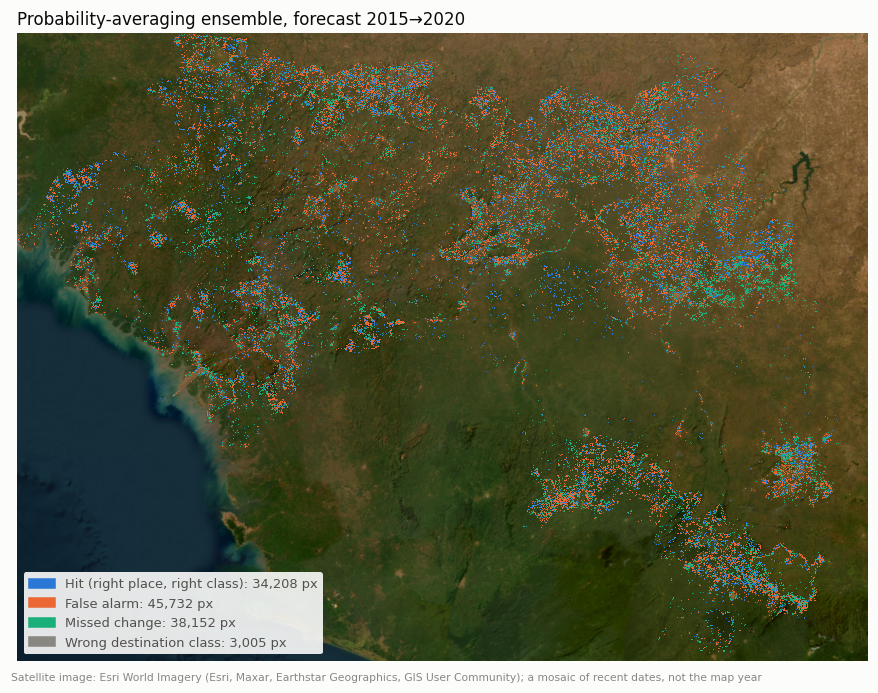

In [7]:
pred = H.read_output_raster(f"{prob.name}/final_probability_ensemble.tif")
emask = H.read_output_raster(f"{prob.name}/evaluation_mask.tif").astype(bool)
codes = H.outcome_map(lc15, lc20, pred, emask)
H.plot_outcome_map(codes, "Probability-averaging ensemble, forecast 2015→2020", profile=H.read_map("Guinea_LandCover_2015.tif")[1])
plt.tight_layout(); plt.show()

## 3 · Model-free rules

How much does a rule with **no training at all** score on the same pixels? Each
rule reads only land-cover maps up to 2015.

In [8]:
rules_dir = H.ensure_run("local_landuse.trivial_rules", "trivial_rules_20260916", [], RERUN["rules"])
tr = H.read_csv(rules_dir / "trivial_rules.csv")
intern_rules = {
    "Every pixel takes the majority class of its eight 2015 neighbours": 22.70,
    "Every pixel takes the majority class of its 2015 3x3 window": 21.10,
    "Revert to the 2010 class if changed 2010->2015": 19.96,
    "Revert to the 2005 class if changed 2010->2015": 17.34,
    "Revert to the modal 2001-2015 class if changed 2010->2015": 17.19,
    "Previous changers take the majority class of their eight 2015 neighbours": 16.61,
    "Continue: previous changers move to their class's most likely destination": 15.18,
    "Revert to the modal class if changed twice (2005->2010 and 2010->2015)": 2.00,
    "No change": 0.00}
rules = tr[tr["role"] == "trivial"].copy()
rules["Intern FoM %"] = rules["rule"].map(intern_rules)
rules = rules.rename(columns={"rule": "Rule", "figure_of_merit_pct": "Ours FoM %"})
rules["Δ FoM (pts)"] = rules["Ours FoM %"] - rules["Intern FoM %"]
rules["Accuracy %"] = 100 * rules["overall_accuracy"]
H.show(rules[["Rule", "Intern FoM %", "Ours FoM %", "Δ FoM (pts)", "Accuracy %"]])

Using saved: outputs/trivial_rules_20260916


Rule,Intern FoM %,"Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts),Accuracy %
Every pixel takes the majority class of its eight 2015 neighbours,22.70,22.70,-0.00,91.07
Every pixel takes the majority class of its 2015 3x3 window,21.10,21.10,-0.00,91.77
Previous changers take the majority class of their eight 2015 neighbours,16.61,16.61,-0.00,92.45
Revert to the 2010 class if changed 2010->2015,19.96,19.96,-0.00,90.23
Revert to the 2005 class if changed 2010->2015,17.34,17.34,0.00,91.64
Revert to the modal 2001-2015 class if changed 2010->2015,17.19,17.19,-0.00,91.76
Continue: previous changers move to their class's most likely destination,15.18,15.18,0.00,89.65
Revert to the modal class if changed twice (2005->2010 and 2010->2015),2.00,2.00,0.00,92.27
No change,0.00,0.00,0.00,92.41


**Giving every pixel the most common class of its eight neighbours scores about
22.7%** with one map, no training and no history. That beats all three
original-style baselines (20.0–20.9%), which use the same structure as the
deployed module. The mechanism is label churn: at 500 m, class boundaries shift
between years, so a pixel that already disagrees with its neighbours is the one
most likely to be relabelled.

This is evidence about **what the metric rewards on this product**, not a
forecasting method. **It is the first test to repeat on ESRI**: if a
neighbour-majority rule also matches the deployed 13.80% there, that changes how
the 13.80% should be presented.

## 4 · A temporally cleaned reference

The standard remedy for label churn (Abercrombie & Friedl, 2016): treat each
pixel's 2001–2024 label sequence as noisy observations of a hidden true class,
fit a hidden Markov model on 2001–2015 labels only, smooth with Viterbi, and
score the *same saved forecasts* against the smoothed 2020 map. No model is
refitted.

In [9]:
hmm, best = H.ensure_hmm_reference("hmm_reference_20260913" + S, prob.name, RERUN["hmm"], python=PY)
hs = H.read_csv(hmm / "hmm_reference_scores.csv")
params = json.loads((hmm / "parameters.json").read_text())
raw_ref = hs[(hs.setting == "raw")].set_index("forecast")
st = hs[(hs.setting == "estimated") & (hs.reference == "stable_start")].set_index("forecast")
fm = hs[(hs.setting == "estimated") & (hs.reference == "full_mask")].set_index("forecast")
print(f"Fitted label accuracy: {params['settings']['estimated']['accuracy']:.3f} (intern 0.972); "
      f"reference change, stable start: {int(st['observed_change_pixels'].iloc[0]):,} px "
      f"(raw {int(raw_ref['observed_change_pixels'].iloc[0]):,}; intern 35,712 of 75,365)")

intern_hmm = {  # forecast label -> (raw, cleaned stable start, cleaned full mask)
    "Original-style transition RF, local reproduction": (20.02, 12.17, 18.98),
    "Original-style binary RF, shared samples/blocks": (20.29, 12.58, 19.48),
    "Initial multiclass RF, shared samples/blocks": (20.91, 12.89, 20.18),
    "Best single member (expanded_typicality_xgb)": (27.25, 15.21, 26.23),
    "Probability-averaging ensemble": (28.06, 15.32, 27.14),
    "Reversion rule: 2010->2015 changers return to 2010 (diagnostic)": (19.96, 1.91, 20.74)}
rows = []
for label in raw_ref.index:
    i = intern_hmm.get(label, (None, None, None))
    rows.append((label, i[0], raw_ref.loc[label, f], i[1], st.loc[label, f], i[2], fm.loc[label, f]))
hmm_table = pd.DataFrame(rows, columns=["Forecast", "Raw: intern", "Raw: ours", "Cleaned, stable start: intern",
                                        "Cleaned, stable start: ours", "Cleaned, full mask: intern",
                                        "Cleaned, full mask: ours"])
H.show(hmm_table)

Using saved run: outputs/hmm_reference_20260913_py314  (best single member: expanded_typicality_xgb)
Fitted label accuracy: 0.972 (intern 0.972); reference change, stable start: 35,712 px (raw 75,365; intern 35,712 of 75,365)


Forecast,Raw: intern,"Raw: Rerun (Python 3.14, xgboost 3.4.1)","Cleaned, stable start: intern","Cleaned, stable start: Rerun (Python 3.14, xgboost 3.4.1)","Cleaned, full mask: intern","Cleaned, full mask: Rerun (Python 3.14, xgboost 3.4.1)"
"Original-style transition RF, local reproduction",20.02,20.00,12.17,12.18,18.98,18.95
"Original-style binary RF, shared samples/blocks",20.29,20.29,12.58,12.59,19.48,19.49
"Initial multiclass RF, shared samples/blocks",20.91,20.82,12.89,12.84,20.18,20.10
Best single member (expanded_typicality_xgb),27.25,27.56,15.21,15.41,26.23,26.50
Probability-averaging ensemble,28.06,28.25,15.32,15.40,27.14,27.29
Reversion rule: 2010->2015 changers return to 2010 (diagnostic),19.96,19.96,1.91,1.91,20.74,20.74


**How sensitive is this to the assumed label accuracy?** The cleaned score
depends mostly on how accurate the land-cover labels are assumed to be:

In [10]:
rows = []
intern_sens = {"estimated": (35712, 15.32, 12.17), "accuracy_0.95": (32453, 14.08, 11.25),
               "accuracy_0.90": (17031, 8.57, 7.26), "accuracy_0.85": (8691, 3.90, 3.88),
               "accuracy_0.75": (3077, 1.52, 1.59)}
ens_label, orig_label = "Probability-averaging ensemble", "Original-style transition RF, local reproduction"
for setting, (ic, ie, io) in intern_sens.items():
    s = hs[(hs.setting == setting) & (hs.reference == "stable_start")].set_index("forecast")
    acc = params["settings"][setting]["accuracy"]
    rows.append((f"{acc:.3f}" + (" (fitted)" if setting == "estimated" else ""),
                 ic, int(s["observed_change_pixels"].iloc[0]), ie, s.loc[ens_label, f], io, s.loc[orig_label, f]))
sens = pd.DataFrame(rows, columns=["Assumed label accuracy", "Reference change: intern", "Reference change: ours",
                                   "Ensemble FoM: intern", "Ensemble FoM: ours", "Original RF FoM: intern",
                                   "Original RF FoM: ours"])
H.show(sens)

Assumed label accuracy,Reference change: intern,"Reference change: Rerun (Python 3.14, xgboost 3.4.1)",Ensemble FoM: intern,"Ensemble FoM: Rerun (Python 3.14, xgboost 3.4.1)",Original RF FoM: intern,"Original RF FoM: Rerun (Python 3.14, xgboost 3.4.1)"
0.972 (fitted),35712,35712,15.32,15.40,12.17,12.18
0.950,32453,32453,14.08,14.17,11.25,11.27
0.900,17031,17031,8.57,8.78,7.26,7.27
0.850,8691,8691,3.90,4.05,3.88,3.90
0.750,3077,3077,1.52,1.54,1.59,1.60


**Result: reproduces.** Same fitted label accuracy, the same cleaned reference
(35,712 changes), and the same pattern. Cleaning removes almost all the changes
that later revert, but also a third of those that persist, so it halves the
reference. **Every model scores lower against it**, and the score depends mainly
on the assumed label accuracy. As the intern concluded, a cleaned reference is a
robustness check, not a better yardstick. The gain of the ensemble over the
original method survives it.

---
## Summary

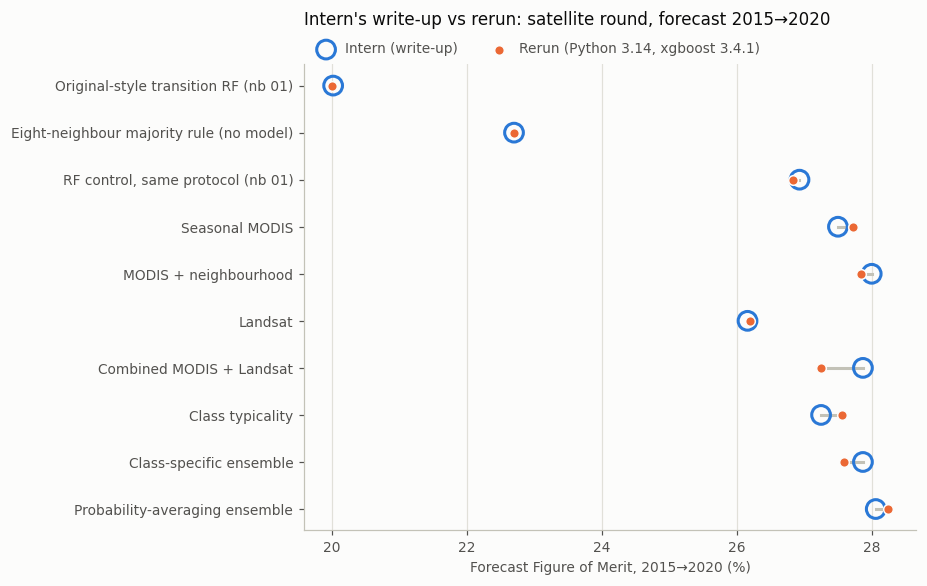

Configuration,Intern FoM %,"Rerun (Python 3.14, xgboost 3.4.1) FoM %",Δ FoM (pts),Tolerance (pts),Reproduces (|Δ| ≤ tolerance)
Original-style transition RF (nb 01),20.02,20.00,-0.02,0.40,yes
Eight-neighbour majority rule (no model),22.70,22.70,-0.00,0.40,yes
"RF control, same protocol (nb 01)",26.93,26.84,-0.09,0.40,yes
Seasonal MODIS,27.50,27.72,0.22,0.85,yes
MODIS + neighbourhood,28.00,27.84,-0.16,0.85,yes
Landsat,26.16,26.20,0.04,0.85,yes
Combined MODIS + Landsat,27.87,27.25,-0.62,0.85,yes
Class typicality,27.25,27.56,0.31,0.85,yes
Class-specific ensemble,27.87,27.59,-0.28,0.85,yes
Probability-averaging ensemble,28.06,28.25,0.19,0.85,yes


In [11]:
headline = pd.DataFrame([
    ("Original-style transition RF (nb 01)", 20.02, raw_ref.loc[orig_label, f], H.TOL),
    ("Eight-neighbour majority rule (no model)", 22.70,
     H.row(rules, "Rule", "Every pixel takes the majority class of its eight 2015 neighbours", "Ours FoM %"), H.TOL),
    ("RF control, same protocol (nb 01)", 26.93, 26.84, H.TOL),
    *[(r["Family"], r["Intern FoM %"], r["Ours FoM %"], H.TOL_XGB_THRESHOLD) for _, r in fam.iterrows()],
    ("Class-specific ensemble", 27.87, src_s[f], H.TOL_XGB_THRESHOLD),
    ("Probability-averaging ensemble", 28.06, pe_s[f], H.TOL_XGB_THRESHOLD),
], columns=["Configuration", "Intern FoM %", "Ours FoM %", "Tolerance"])
headline = H.compare([(c, i, o, None, None, t) for c, i, o, t in headline.values.tolist()])
H.plot_dumbbell(headline, "Intern's write-up vs rerun: satellite round, forecast 2015→2020")
plt.tight_layout(); plt.show()
H.show(headline[["Configuration", "Intern FoM %", "Ours FoM %", "Δ FoM (pts)", "Tolerance (pts)", H.REPRODUCES]])

| Step | Verdict |
|---|---|
| Satellite downloads (nb 02) | Identical coverage and scene selection |
| Five satellite families | Same models selected. Forecasts within ±0.31 except combined MODIS + Landsat (−0.62; validation matches) |
| Class-specific ensemble | Reproduces (27.59 vs 27.87) |
| **Probability-averaging ensemble** | **28.25% vs 28.06% (+0.19).** Same starting member, three of four members, same accuracy; the false-alarm reduction reproduces |
| Model-free rules | Exact (deterministic) |
| Cleaned reference | Reproduces. Every score falls; robustness check only |

**The intern's results are independently validated.** Every model their validation selected is
chosen again here, and the headline improvement over the original-style method
is reproduced: **+8.3 points** here against their +8.0. The one forecast more than
0.4 point away (combined MODIS + Landsat, −0.62) is within the ±0.85 tolerance for
threshold-tuned XGBoost.

**What to carry to the ESRI module, in order of evidence:**
1. **Model-free neighbour-majority rule and label-reversion audit.** Cheap. They
   tell us whether the deployed 13.80% beats a rule with no training.
2. **Land-cover history features** (+2 to +3 points, nb 01).
3. **Seasonal vegetation with neighbourhood context** (+1.0 point over the control).
   Dry-season Landsat alone adds nothing.
4. **Probability averaging across models** (+0.7 to +0.8 over the best single model,
   by cutting false alarms).

In [12]:
out = H.SUMMARY; out.mkdir(parents=True, exist_ok=True)
for frame, name in [(fam, "03_families"), (typ, "03_typicality_pairs"), (ens, "03_ensembles"),
                    (rules, "03_model_free_rules"), (hmm_table, "03_hmm_reference"), (sens, "03_hmm_sensitivity"),
                    (headline, "03_summary")]:
    H.relabel(frame).to_csv(out / f"{name}.csv", index=False)
print("Saved tables to", out.relative_to(H.ROOT))

Saved tables to outputs\summary
